# Imports

In [1]:
import os

cwd = os.getcwd()
os.chdir("/home/yoshi0428/PycharmProjects/osu-predict")

In [2]:
import json
import pickle
from collections import Counter
from datetime import datetime

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GroupKFold,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from beatmap_classifier.classifier.augment_faster import (
    extract_movement_features_from_X,
)
from beatmap_classifier.classifier.cnn_model import CNNModel
from beatmap_classifier.classifier.utils_training import (
    get_additional_features,
    get_data,
    load_pytorch_models,
    pad_sequences_pt,
    plot_training_history,
    predict_proba,
    save_vector_normalization,
    train_and_evaluate,
)

# Model Testing

Go run test_model.py

# Initializing some Data

In [3]:
TOURNAMENT_MODS = {
    "nm1": "NM",
    "nm2": "NM",
    "nm3": "NM",
    "nm4": "NM",
    "nm5": "NM",
    "nm6": "NM",
    "hd1": "HD",
    "hd2": "HD",
    "hd3": "HD",
    "hr1": "HR",
    "hr2": "HR",
    "hr3": "HR",
    "dt1": "DT",
    "dt2_and_dt3": "DT",
    "dt4": "DT",
    "tiebreaker": "NM",
}

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

db_path = "./beatmap_classifier/unexpanded_beatmaps.db"

X, y, beatmap_ids = get_data(db_path)
raw_additional_features, normalized_additional_features = get_additional_features(
    db_path, y, beatmap_ids
)

# Precompute must scale vectors exactly like get_data() did, so save the
# scales next to the model (read by precompute_nm1-5.py and test_model.py).
save_vector_normalization(db_path, "./beatmap_classifier/models/eval/vector_normalization.json")

Max Vector Length: 500.0
Max Time Diff: 86087.0
Tournament-labeled beatmaps: 3923
Max Vector Count: 6309
Original beatmaps: 3923


{'max_time_diff': 86087.0, 'max_vector_length': 500.0}

In [25]:
# Get the mod associated with each tournament label
mods_flattened = [
    TOURNAMENT_MODS[label] if TOURNAMENT_MODS[label] else "NM" for label in y
]

raw_additional_features_array = np.array(
    [
        raw_additional_features[(beatmap_id, mod)]
        for beatmap_id, mod in zip(beatmap_ids, mods_flattened)
    ]
)

normalized_additional_features_array = np.array(
    [
        normalized_additional_features[(beatmap_id, mod)]
        for beatmap_id, mod in zip(beatmap_ids, mods_flattened)
    ]
)

In [5]:
(
    X_train,
    X_test,
    y_train,
    y_test,
    beatmap_ids_train,
    beatmap_ids_test,
) = train_test_split(
    X,
    y,
    beatmap_ids,
    test_size=0.2,
    random_state=42,
)

print(f"Final train size: {len(X_train)}")
print(f"Final test size:  {len(X_test)}")

Final train size: 3138
Final test size:  785


In [6]:
# Encode labels
label_encoder = LabelEncoder()
label_encoder.fit(y)

with open("./beatmap_classifier/models/eval/label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

y_train_numerical = label_encoder.transform(y_train)
y_test_numerical = label_encoder.transform(y_test)
num_classes = len(label_encoder.classes_)

y_train_numerical = torch.tensor(y_train_numerical, dtype=torch.long)
y_test_numerical = torch.tensor(y_test_numerical, dtype=torch.long)

# Pad sequences
sequence_lengths = np.array([len(seq) for seq in X])
max_length = int(np.percentile(sequence_lengths, 99))
max_length = 2 ** int(np.ceil(np.log2(max_length)))
max_length = min(max_length, 4096)

print(f"Using max sequence length: {max_length}")

X_train = pad_sequences_pt(X_train, maxlen=max_length, dtype=torch.float32)

X_test = pad_sequences_pt(X_test, maxlen=max_length, dtype=torch.float32)

print("Before metadata:")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

Using max sequence length: 4096
Before metadata:
X_train: torch.Size([3138, 4096, 8])
X_test:  torch.Size([785, 4096, 8])


In [7]:
class_counts = Counter(y_train_numerical.numpy())

for cls, count in sorted(class_counts.items()):
    print(f"Class {cls}: {count}")

print(dict(enumerate(label_encoder.classes_)))

Class 0: 693
Class 1: 704
Class 2: 745
Class 3: 608
Class 4: 388
{0: np.str_('nm1'), 1: np.str_('nm2'), 2: np.str_('nm3'), 3: np.str_('nm4'), 4: np.str_('nm5')}


In [8]:
# Extract geometric summary vectors for each row in X_train and X_test
movement_features_train = np.array(
    [extract_movement_features_from_X(X_train[i]) for i in range(len(X_train))],
    dtype=np.float32,
)

movement_features_test = np.array(
    [extract_movement_features_from_X(X_test[i]) for i in range(len(X_test))],
    dtype=np.float32,
)

# NOTICE THAT WE SWITCH FROM NORMALIZED TO RAW ADDITIONAL FEATURES
# BECAUSE XGBOOST DOESN'T NEED SCALING

# Extract SQLite metadata features corresponding to train/test IDs
mods_flattened_train = [TOURNAMENT_MODS.get(label, "NM") for label in y_train]

sql_features_train = np.array(
    [
        raw_additional_features[(b_id, mod)]
        for b_id, mod in zip(beatmap_ids_train, mods_flattened_train)
    ],
    dtype=np.float32,
)

mods_flattened_test = [TOURNAMENT_MODS.get(label, "NM") for label in y_test]

sql_features_test = np.array(
    [
        raw_additional_features.get((b_id, mod))
        for b_id, mod in zip(beatmap_ids_test, mods_flattened_test)
    ],
    dtype=np.float32,
)

# Concatenate (SQL metadata + Movement geometric summary)
X_additional_train = np.hstack([sql_features_train, movement_features_train])
X_additional_test = np.hstack([sql_features_test, movement_features_test])

print(f"Full meta tabular train shape: {X_additional_train.shape}")
print(f"Full meta tabular test shape:  {X_additional_test.shape}")

Full meta tabular train shape: (3138, 24)
Full meta tabular test shape:  (785, 24)


# CNN Model (SKIP TO XGBOOST IF DESIRED)

--- Training Meta Fold 1/5 ---
Epoch 1/50 - loss: 2.2220 - acc: 0.5112 - val_loss: 1.0144 - val_acc: 0.7038
Epoch 2/50 - loss: 1.0340 - acc: 0.6865 - val_loss: 0.9208 - val_acc: 0.7500
Epoch 3/50 - loss: 0.9727 - acc: 0.7319 - val_loss: 0.8989 - val_acc: 0.7452
Epoch 4/50 - loss: 0.9046 - acc: 0.7594 - val_loss: 0.8010 - val_acc: 0.8153
Epoch 5/50 - loss: 0.8860 - acc: 0.7753 - val_loss: 0.7537 - val_acc: 0.8328
Epoch 6/50 - loss: 0.8222 - acc: 0.8008 - val_loss: 0.7805 - val_acc: 0.8185
Epoch 7/50 - loss: 0.7961 - acc: 0.8139 - val_loss: 0.7173 - val_acc: 0.8487
Epoch 8/50 - loss: 0.7903 - acc: 0.8287 - val_loss: 0.8052 - val_acc: 0.8041
Epoch 9/50 - loss: 0.7752 - acc: 0.8271 - val_loss: 0.7200 - val_acc: 0.8328
Epoch 10/50 - loss: 0.7525 - acc: 0.8534 - val_loss: 0.6823 - val_acc: 0.8646
Epoch 11/50 - loss: 0.7396 - acc: 0.8574 - val_loss: 0.7442 - val_acc: 0.8392
Epoch 12/50 - loss: 0.7376 - acc: 0.8506 - val_loss: 0.6725 - val_acc: 0.8678
Epoch 13/50 - loss: 0.7261 - acc: 0.8566 -

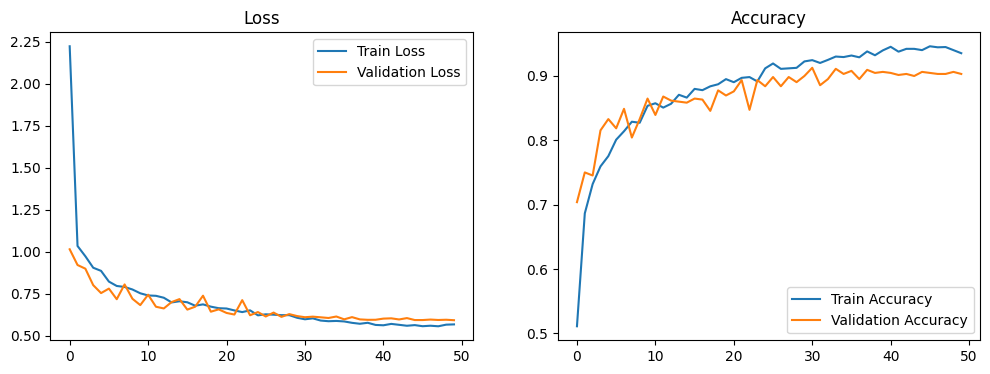

--- Training Meta Fold 2/5 ---
Epoch 1/50 - loss: 2.5519 - acc: 0.5020 - val_loss: 0.9819 - val_acc: 0.6975
Epoch 2/50 - loss: 1.0343 - acc: 0.6717 - val_loss: 0.9490 - val_acc: 0.7293
Epoch 3/50 - loss: 0.9491 - acc: 0.7367 - val_loss: 0.8896 - val_acc: 0.7627
Epoch 4/50 - loss: 0.9233 - acc: 0.7721 - val_loss: 0.8938 - val_acc: 0.7564
Epoch 5/50 - loss: 0.8773 - acc: 0.7777 - val_loss: 0.8711 - val_acc: 0.7611
Epoch 6/50 - loss: 0.8180 - acc: 0.8088 - val_loss: 0.7687 - val_acc: 0.8360
Epoch 7/50 - loss: 0.8068 - acc: 0.8183 - val_loss: 0.7582 - val_acc: 0.8392
Epoch 8/50 - loss: 0.7840 - acc: 0.8327 - val_loss: 0.8763 - val_acc: 0.7659
Epoch 9/50 - loss: 0.7647 - acc: 0.8363 - val_loss: 0.6904 - val_acc: 0.8551
Epoch 10/50 - loss: 0.7600 - acc: 0.8418 - val_loss: 0.6987 - val_acc: 0.8583
Epoch 11/50 - loss: 0.7411 - acc: 0.8530 - val_loss: 0.7117 - val_acc: 0.8519
Epoch 12/50 - loss: 0.7243 - acc: 0.8574 - val_loss: 0.7208 - val_acc: 0.8583
Epoch 13/50 - loss: 0.7210 - acc: 0.8574 -

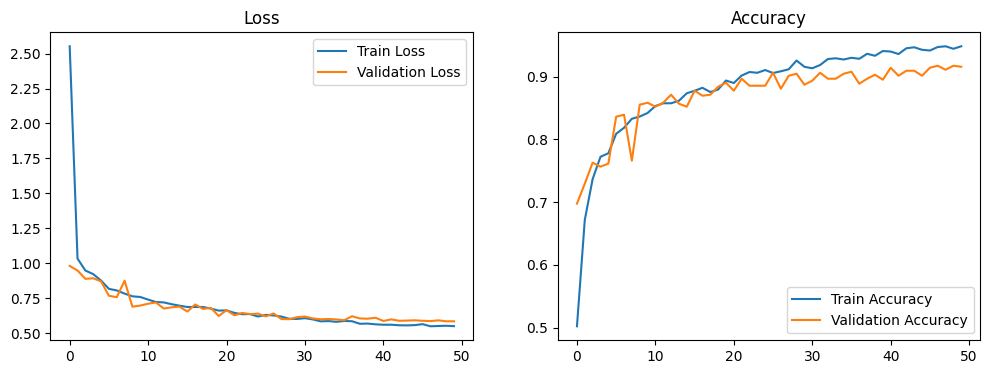

--- Training Meta Fold 3/5 ---
Epoch 1/50 - loss: 2.0572 - acc: 0.4960 - val_loss: 0.9884 - val_acc: 0.7229
Epoch 2/50 - loss: 1.0719 - acc: 0.6637 - val_loss: 0.8759 - val_acc: 0.7755
Epoch 3/50 - loss: 0.9822 - acc: 0.7247 - val_loss: 0.8514 - val_acc: 0.7755
Epoch 4/50 - loss: 0.9194 - acc: 0.7602 - val_loss: 0.7110 - val_acc: 0.8551
Epoch 5/50 - loss: 0.8532 - acc: 0.7833 - val_loss: 0.7381 - val_acc: 0.8519
Epoch 6/50 - loss: 0.8329 - acc: 0.8072 - val_loss: 0.6779 - val_acc: 0.8742
Epoch 7/50 - loss: 0.8190 - acc: 0.8072 - val_loss: 0.6995 - val_acc: 0.8678
Epoch 8/50 - loss: 0.7852 - acc: 0.8283 - val_loss: 0.7677 - val_acc: 0.8312
Epoch 9/50 - loss: 0.7743 - acc: 0.8414 - val_loss: 0.6654 - val_acc: 0.8901
Epoch 10/50 - loss: 0.7560 - acc: 0.8482 - val_loss: 0.6467 - val_acc: 0.9092
Epoch 11/50 - loss: 0.7498 - acc: 0.8458 - val_loss: 0.6528 - val_acc: 0.8933
Epoch 12/50 - loss: 0.7428 - acc: 0.8610 - val_loss: 0.6580 - val_acc: 0.8885
Epoch 13/50 - loss: 0.7307 - acc: 0.8570 -

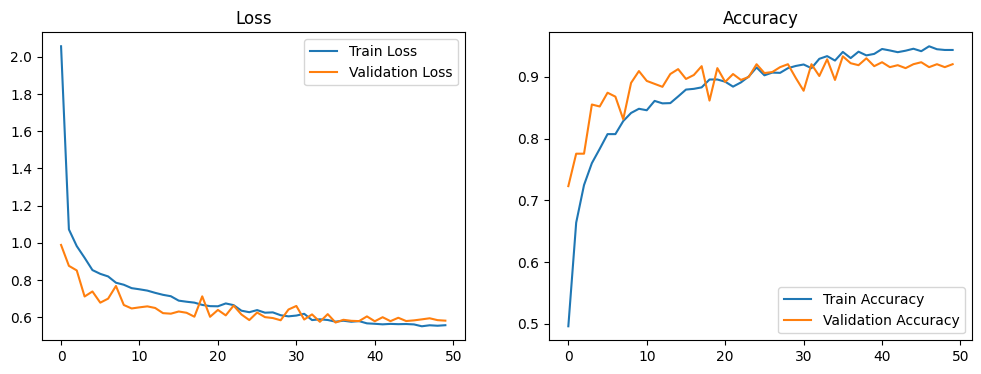

--- Training Meta Fold 4/5 ---
Epoch 1/50 - loss: 2.4048 - acc: 0.5094 - val_loss: 0.9579 - val_acc: 0.7081
Epoch 2/50 - loss: 1.0694 - acc: 0.6595 - val_loss: 0.9407 - val_acc: 0.7640
Epoch 3/50 - loss: 1.0022 - acc: 0.7025 - val_loss: 0.8156 - val_acc: 0.8166
Epoch 4/50 - loss: 0.9346 - acc: 0.7555 - val_loss: 0.7999 - val_acc: 0.8214
Epoch 5/50 - loss: 0.8589 - acc: 0.7909 - val_loss: 0.7605 - val_acc: 0.8293
Epoch 6/50 - loss: 0.8335 - acc: 0.8061 - val_loss: 0.7423 - val_acc: 0.8309
Epoch 7/50 - loss: 0.8160 - acc: 0.8128 - val_loss: 0.7159 - val_acc: 0.8389
Epoch 8/50 - loss: 0.7819 - acc: 0.8375 - val_loss: 0.6962 - val_acc: 0.8772
Epoch 9/50 - loss: 0.7751 - acc: 0.8327 - val_loss: 0.6985 - val_acc: 0.8708
Epoch 10/50 - loss: 0.7655 - acc: 0.8431 - val_loss: 0.6722 - val_acc: 0.8900
Epoch 11/50 - loss: 0.7415 - acc: 0.8507 - val_loss: 0.7084 - val_acc: 0.8501
Epoch 12/50 - loss: 0.7278 - acc: 0.8606 - val_loss: 0.6557 - val_acc: 0.8884
Epoch 13/50 - loss: 0.7162 - acc: 0.8602 -

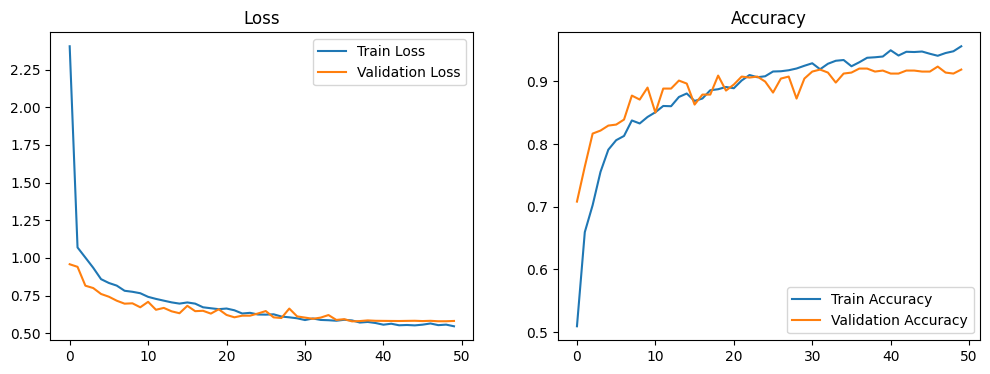

--- Training Meta Fold 5/5 ---
Epoch 1/50 - loss: 2.2547 - acc: 0.4918 - val_loss: 0.9677 - val_acc: 0.7161
Epoch 2/50 - loss: 1.0469 - acc: 0.6675 - val_loss: 0.9117 - val_acc: 0.7496
Epoch 3/50 - loss: 0.9671 - acc: 0.7252 - val_loss: 0.8613 - val_acc: 0.7799
Epoch 4/50 - loss: 0.9044 - acc: 0.7698 - val_loss: 0.8140 - val_acc: 0.7959
Epoch 5/50 - loss: 0.8593 - acc: 0.7921 - val_loss: 0.7665 - val_acc: 0.8214
Epoch 6/50 - loss: 0.8434 - acc: 0.7977 - val_loss: 0.7928 - val_acc: 0.8134
Epoch 7/50 - loss: 0.8239 - acc: 0.8172 - val_loss: 0.7293 - val_acc: 0.8565
Epoch 8/50 - loss: 0.8028 - acc: 0.8180 - val_loss: 0.7033 - val_acc: 0.8612
Epoch 9/50 - loss: 0.7792 - acc: 0.8419 - val_loss: 0.7398 - val_acc: 0.8501
Epoch 10/50 - loss: 0.7486 - acc: 0.8463 - val_loss: 0.7017 - val_acc: 0.8501
Epoch 11/50 - loss: 0.7661 - acc: 0.8375 - val_loss: 0.7176 - val_acc: 0.8405
Epoch 12/50 - loss: 0.7241 - acc: 0.8574 - val_loss: 0.6569 - val_acc: 0.8756
Epoch 13/50 - loss: 0.7208 - acc: 0.8674 -

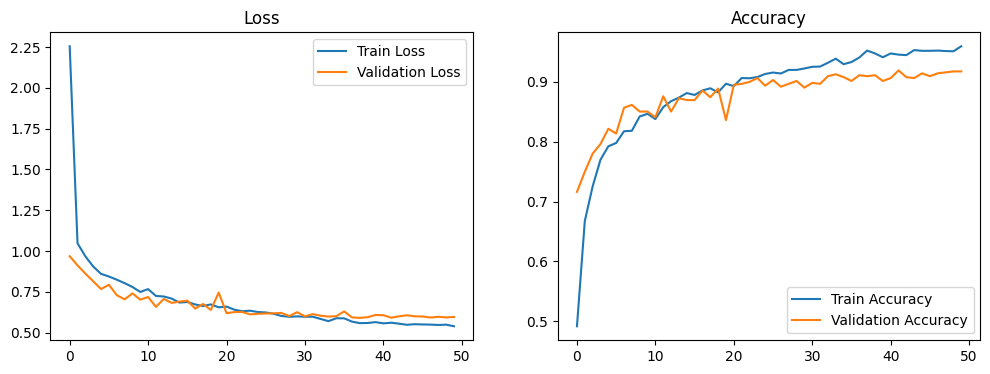

In [9]:
meta_bagging_models = []
beatmap_ids_train = np.array(beatmap_ids_train)

# Initialize empty matrix for clean Out-Of-Fold CNN probability predictions
oof_cnn_predictions = np.zeros((len(X_train), num_classes), dtype=np.float32)

# NOTE: groups are beatmap ids, which are unique, so this is plain KFold
# (mapset difficulties are NOT kept together)
gkf = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    gkf.split(X_train, y_train_numerical, groups=beatmap_ids_train)
):
    print(f"--- Training Meta Fold {fold + 1}/5 ---")

    # Split raw unaugmented fold data
    X_fold_train, y_fold_train = X_train[train_idx], y_train_numerical[train_idx]
    X_fold_val, y_fold_val = X_train[val_idx], y_train_numerical[val_idx]

    # Convert validation fold to PyTorch Tensor (permuted to (B, C, L))
    X_fold_val = torch.as_tensor(X_fold_val, dtype=torch.float32).permute(0, 2, 1)
    y_fold_val = torch.as_tensor(y_fold_val, dtype=torch.long)

    X_fold_train = torch.as_tensor(X_fold_train, dtype=torch.float32).permute(0, 2, 1)

    # Train CNN model for this fold. Flips are applied randomly per batch
    # inside train_and_evaluate (random_flips=True), so no augment_dataset().
    model, history = train_and_evaluate(
        X_fold_train,
        y_fold_train,
        X_fold_val,
        y_fold_val,
        input_channels=X_fold_train.shape[1],
        num_classes=num_classes,
        max_length=max_length,
        learning_rate=0.001,
        dropout_rate=0.3,  # old: 0.5
        l2_reg=0.001,
        batch_size=32,  # old: 128 (32 was clearly better in CV)
        epochs=50,  # old: 30
        patience=15,
    )
    plot_training_history(history)
    meta_bagging_models.append(model)

    # Generate Out-of-Fold predictions for the unaugmented validation set ONLY
    probs = predict_proba(model, X_fold_val, device)

    # Store clean OOF predictions in the array
    oof_cnn_predictions[val_idx] = probs

In [10]:
os.makedirs("./beatmap_classifier/models/eval/bagged_models", exist_ok=True)

for i, model in enumerate(meta_bagging_models):
    torch.save(model.state_dict(), f"./beatmap_classifier/models/eval/bagged_models/bagged_cnn_model_{i}.pth")

np.save("./beatmap_classifier/models/eval/oof_cnn_predictions.npy", oof_cnn_predictions)
np.save("./beatmap_classifier/models/eval/y_train_numerical.npy", y_train_numerical)
np.save("./beatmap_classifier/models/eval/beatmap_ids_train.npy", np.array(beatmap_ids_train))

# XGBoost Meta Model

### Load Models and Data

In [11]:
model_kwargs = {
    "input_channels": 8,
    "num_classes": num_classes,
    "max_length": max_length,
    "dropout_rate": 0.3,
}

meta_bagging_models = load_pytorch_models(
    model_folder="./beatmap_classifier/models/eval/bagged_models",
    model_class=CNNModel,
    model_kwargs=model_kwargs,
    device=device,
)

oof_cnn_predictions = np.load("./beatmap_classifier/models/eval/oof_cnn_predictions.npy")
y_train_numerical = np.load("./beatmap_classifier/models/eval/y_train_numerical.npy")

print(f"Loaded {len(meta_bagging_models)} CNN models")

Loaded 5 CNN models


### Test the bagging models
93% is already pretty good, but we will see soon that we can improve it

In [12]:
# Generate Test probabilities by averaging predictions across all fold models
X_test_tensor = torch.as_tensor(X_test, dtype=torch.float32).permute(0, 2, 1)
test_probs_list = [
    predict_proba(model, X_test_tensor, device) for model in meta_bagging_models
]

bagged_test_predictions = np.mean(test_probs_list, axis=0)
bagged_test_predictions_numerical = np.argmax(bagged_test_predictions, axis=1)

score = accuracy_score(y_test_numerical, bagged_test_predictions_numerical)
cm = confusion_matrix(y_test_numerical, bagged_test_predictions_numerical)
report = classification_report(
    y_test_numerical,
    bagged_test_predictions_numerical,
    zero_division=0,
    target_names=[
        "NM1",
        "NM2",
        "NM3",
        "NM4",
        "NM5",
    ],  # "DT1", "DT2_and_DT3", "HD2", "HR1", "HR2",
)

print("Classification Report:\n", report)
print("Confusion Matrix:\n", cm)
print(f"Accuracy: {score}")

Classification Report:
               precision    recall  f1-score   support

         NM1       0.95      0.98      0.96       202
         NM2       0.96      0.95      0.96       163
         NM3       0.92      0.92      0.92       171
         NM4       0.89      0.90      0.90       153
         NM5       0.93      0.90      0.91        96

    accuracy                           0.93       785
   macro avg       0.93      0.93      0.93       785
weighted avg       0.93      0.93      0.93       785

Confusion Matrix:
 [[197   0   2   3   0]
 [  2 155   0   2   4]
 [  6   1 157   7   0]
 [  0   2  11 138   2]
 [  2   3   0   5  86]]
Accuracy: 0.9337579617834395


### Setup

Make sure that this setup matches in `/beatmap_recommender/recommender_db_setup/precompute_nm1-5.py` whenever you're done.

In [13]:
sql_feature_names = [
    "ar",
    "od",
    "circle_size",
    "star_rating",
    "bpm",
    "max_combo",
    "length_seconds",
    "object_count",
    "pp",
    "pp_aim",
    "pp_speed",
    "pp_acc",
]

movement_feature_names = [
    "slider_ratio",
    "slider_length_std",
    "speed_std",
    "speed_change_std",
    "speed_change_max",
    "angle_std",
    "angle_mean",
    "rhythm_variance",
    "distance_mean",
    "speed_change_95th",
    "angle_90th",
    "sharp_turn_ratio",
]

cnn_feature_names = [
    "CNN_NM1",
    "CNN_NM2",
    "CNN_NM3",
    "CNN_NM4",
    "CNN_NM5",
]

additional_feature_names = sql_feature_names + movement_feature_names

In [14]:
print(additional_feature_names)

['ar', 'od', 'circle_size', 'star_rating', 'bpm', 'max_combo', 'length_seconds', 'object_count', 'pp', 'pp_aim', 'pp_speed', 'pp_acc', 'slider_ratio', 'slider_length_std', 'speed_std', 'speed_change_std', 'speed_change_max', 'angle_std', 'angle_mean', 'rhythm_variance', 'distance_mean', 'speed_change_95th', 'angle_90th', 'sharp_turn_ratio']


You can add more feature groups here, if desired

In [15]:
# GROUP 1
excluded_features = {
}

group1_features = [
    feature for feature in additional_feature_names if feature not in excluded_features
]

# GROUP 2
# excluded_features = {
#     "speed_change_95th",
# }
#
# group2_features = [
#     feature
#     for feature in additional_feature_names
#     if feature not in excluded_features
# ]
#

# COMBINE ALL GROUPS TOGETHER
additional_feature_groups = {
    "group1": group1_features,
    # "group2": group2_features,
}

feature_indices = {
    group_name: [additional_feature_names.index(feature) for feature in features]
    for group_name, features in additional_feature_groups.items()
}

In [16]:
def make_xgb(params):
    return XGBClassifier(
        random_state=42,
        objective="multi:softprob",
        num_class=5,
        eval_metric="mlogloss",
        **params,
    )


def optimize_xgb_feature_set(
    X_additional_train,
    oof_cnn_predictions,
    y_train,
    indices,
    n_trials=50,
    seed=42,
):
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 250, 750, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
            "max_depth": trial.suggest_int("max_depth", 2, 8),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        }

        scores = []

        for train_idx, valid_idx in cv.split(X_meta_train, y_train):
            X_train = X_meta_train[train_idx]
            X_valid = X_meta_train[valid_idx]

            y_train_fold = y_train[train_idx]
            y_valid_fold = y_train[valid_idx]

            model = make_xgb(params)
            model.fit(
                X_train, y_train_fold, eval_set=[(X_valid, y_valid_fold)], verbose=False
            )
            pred = model.predict(X_valid)

            scores.append(
                f1_score(y_valid_fold, pred, average="macro", zero_division=0)
            )

        return np.mean(scores)

    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return study


def cv_evaluate_feature_set(
    indices,
    X_additional_train,
    oof_cnn_predictions,
    y_train,
    params,
    seed=42,
):
    # Scores a feature set with CV on the train split only, so feature selection
    # never sees the test set
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed,
    )

    pred = cross_val_predict(make_xgb(params), X_meta_train, y_train, cv=cv)

    cm = confusion_matrix(y_train, pred)

    return {
        "accuracy": accuracy_score(y_train, pred),
        "macro_f1": f1_score(y_train, pred, average="macro"),
        "nm3_to_nm4": cm[2, 3],
        "nm4_to_nm3": cm[3, 2],
    }


def fit_meta_model(indices, X_additional_train, oof_cnn_predictions, y_train, params):
    X_meta_train = np.hstack(
        [
            oof_cnn_predictions,
            X_additional_train[:, indices],
        ]
    )

    model = make_xgb(params)
    model.fit(X_meta_train, y_train)
    return model

In [17]:
def get_feature_indices(feature_names, selected_features):
    missing = [name for name in selected_features if name not in feature_names]

    if missing:
        raise ValueError(f"Features not found: {missing}")

    return [feature_names.index(name) for name in selected_features]

### Compare the XGBoost Classifiers within Feature Groups

Skip this cell if you're trying to compared changed features, and already obtained some good params in `./models/xgb_best_params.json`

Change n_trials if needed.

In [18]:
studies = {}
best_params = {}

for group_name, indices in feature_indices.items():
    study = optimize_xgb_feature_set(
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        indices=indices,
        n_trials=100,
    )

    studies[group_name] = study

    best_params[group_name] = {
        "macro_f1": study.best_value,
        "params": study.best_params,
    }

    print(f"\nBest macro F1: {study.best_value:.4f}")
    print("Best parameters:")

    for param, value in study.best_params.items():
        print(f"  {param}: {value}")

# Save this entire experiment as a new file
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = f"./beatmap_classifier/models/eval/xgb_params/xgb_best_params_{timestamp}.json"

with open(output_path, "w") as f:
    json.dump(best_params, f, indent=4)

print(f"\nSaved best parameters to: {output_path}")

[I 2026-10-19 16:55:27,606] A new study created in memory with name: no-name-39a66a97-b9b6-4374-a6d0-b9d6bafd5316
Best trial: 0. Best value: 0.920098:   1%|          | 1/100 [00:03<05:38,  3.42s/it]

[I 2026-10-19 16:55:31,028] Trial 0 finished with value: 0.920097767332315 and parameters: {'n_estimators': 450, 'learning_rate': 0.0862735828664018, 'max_depth': 7, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 0.0001707396743152812, 'reg_lambda': 5.3994844097874335}. Best is trial 0 with value: 0.920097767332315.


Best trial: 1. Best value: 0.923225:   2%|▏         | 2/100 [00:05<04:39,  2.85s/it]

[I 2026-10-19 16:55:33,476] Trial 1 finished with value: 0.9232254057447282 and parameters: {'n_estimators': 550, 'learning_rate': 0.04170553216181044, 'max_depth': 2, 'min_child_weight': 10, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 0.000533703276260396, 'reg_lambda': 0.2327067708383781}. Best is trial 1 with value: 0.9232254057447282.


Best trial: 2. Best value: 0.923258:   3%|▎         | 3/100 [00:09<05:17,  3.27s/it]

...

[I 2026-10-19 17:03:49,979] Trial 97 finished with value: 0.929183098381418 and parameters: {'n_estimators': 650, 'learning_rate': 0.00888871056693728, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.8229933189947031, 'colsample_bytree': 0.7340459065545952, 'reg_alpha': 0.00010000359783358828, 'reg_lambda': 0.2551305759897203}. Best is trial 13 with value: 0.9301198620287618.


Best trial: 13. Best value: 0.93012:  99%|█████████▉| 99/100 [08:28<00:05,  5.66s/it]

[I 2026-10-19 17:03:56,054] Trial 98 finished with value: 0.9291321960225242 and parameters: {'n_estimators': 600, 'learning_rate': 0.009687153813542671, 'max_depth': 5, 'min_child_weight': 7, 'subsample': 0.7475821442526621, 'colsample_bytree': 0.7764687130139755, 'reg_alpha': 0.0008497965698165741, 'reg_lambda': 0.4118817287636214}. Best is trial 13 with value: 0.9301198620287618.


Best trial: 13. Best value: 0.93012: 100%|██████████| 100/100 [08:34<00:00,  5.14s/it]

[I 2026-10-19 17:04:01,779] Trial 99 finished with value: 0.9275115127226737 and parameters: {'n_estimators': 500, 'learning_rate': 0.006429760161144162, 'max_depth': 5, 'min_child_weight': 6, 'subsample': 0.8074980661731016, 'colsample_bytree': 0.9226908853275302, 'reg_alpha': 0.0015995401446909194, 'reg_lambda': 0.48574330923991055}. Best is trial 13 with value: 0.9301198620287618.

Best macro F1: 0.9301
Best parameters:
  n_estimators: 600
  learning_rate: 0.009305000701755422
  max_depth: 8
  min_child_weight: 7
  subsample: 0.8056891692692756
  colsample_bytree: 0.9156963747476535
  reg_alpha: 0.012185426398141614
  reg_lambda: 2.4055267052509994

Saved best parameters to: ./beatmap_classifier/models/eval/xgb_params/xgb_best_params_20261019_170401.json


### Compare the XGBoost Classifiers by removing single features in a Feature Group
NOTE: value maximized in previous cell is Macro F1 Score. The comparisons below are scored with 5-fold CV on the train split, so the test set stays untouched until the final cell.

We're gonna load the best params here.

In [19]:
JSON_FILE = "xgb_best_params_20261019_170401.json"

with open(f"./beatmap_classifier/models/eval/xgb_params/{JSON_FILE}", "r") as f:
    best_params = json.load(f)

best_params

{'group1': {'macro_f1': 0.9301198620287618,
  'params': {'n_estimators': 600,
   'learning_rate': 0.009305000701755422,
   'max_depth': 8,
   'min_child_weight': 7,
   'subsample': 0.8056891692692756,
   'colsample_bytree': 0.9156963747476535,
   'reg_alpha': 0.012185426398141614,
   'reg_lambda': 2.4055267052509994}}}

In [20]:
for group_name, indices in feature_indices.items():
    params = best_params[group_name]["params"]

    print("=" * 80)
    print(f"FEATURE GROUP: {group_name}")
    print(f"Number of features: {len(indices)}")
    print(f"Features:")
    print([additional_feature_names[i] for i in indices])

    results = cv_evaluate_feature_set(
        indices=indices,
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        params=params,
    )

    print(
        f"cv_accuracy={results['accuracy'] * 100:.2f}% | "
        f"cv_macro_f1={results['macro_f1']:.4f}"
    )

FEATURE GROUP: group1
Number of features: 24
Features:
['ar', 'od', 'circle_size', 'star_rating', 'bpm', 'max_combo', 'length_seconds', 'object_count', 'pp', 'pp_aim', 'pp_speed', 'pp_acc', 'slider_ratio', 'slider_length_std', 'speed_std', 'speed_change_std', 'speed_change_max', 'angle_std', 'angle_mean', 'rhythm_variance', 'distance_mean', 'speed_change_95th', 'angle_90th', 'sharp_turn_ratio']
cv_accuracy=93.34% | cv_macro_f1=0.9302


Set the desired group from the JSON in `FEATURE_GROUP`.

You might want to go back and forth, iteratively removing features from the selected group after seeing this cell's results. Keep doing this until CV accuracy is maximized.

In [21]:
FEATURE_GROUP = "group1"

params = best_params[FEATURE_GROUP]["params"]
all_features = additional_feature_groups[FEATURE_GROUP]
indices = get_feature_indices(additional_feature_names, all_features)

# --------------------------------------------------------------
# Baseline
# --------------------------------------------------------------
baseline = cv_evaluate_feature_set(
    indices=indices,
    X_additional_train=X_additional_train,
    oof_cnn_predictions=oof_cnn_predictions,
    y_train=y_train_numerical,
    params=params,
)

print("Baseline (CV on train):")
print(baseline)

baseline_acc = baseline["accuracy"]
baseline_f1 = baseline["macro_f1"]

# --------------------------------------------------------------
# Leave-one-feature-out evaluation
# --------------------------------------------------------------
array_results = []

for removed_feature in all_features:
    remaining_features = [
        feature for feature in all_features if feature != removed_feature
    ]

    remaining_indices = get_feature_indices(
        additional_feature_names, remaining_features
    )

    results = cv_evaluate_feature_set(
        indices=remaining_indices,
        X_additional_train=X_additional_train,
        oof_cnn_predictions=oof_cnn_predictions,
        y_train=y_train_numerical,
        params=params,
    )

    dict_results = {
        "removed": removed_feature,
        "accuracy": results["accuracy"],
        "macro_f1": results["macro_f1"],
        "acc_delta": results["accuracy"] - baseline_acc,
        "f1_delta": results["macro_f1"] - baseline_f1,
        "nm3_to_nm4": results["nm3_to_nm4"],
        "nm4_to_nm3": results["nm4_to_nm3"],
    }

    array_results.append(dict_results)

results_df = pd.DataFrame(array_results)

results_df = results_df.sort_values("acc_delta", ascending=False)

print(results_df.to_string(index=False))
print("=" * 100)

Baseline (CV on train):
{'accuracy': 0.9333970681963034, 'macro_f1': 0.9302294741756475, 'nm3_to_nm4': np.int64(29), 'nm4_to_nm3': np.int64(30)}
          removed  accuracy  macro_f1  acc_delta  f1_delta  nm3_to_nm4  nm4_to_nm3
    distance_mean  0.933397  0.930485   0.000000  0.000256          29          30
     slider_ratio  0.933397  0.930483   0.000000  0.000254          30          30
       angle_mean  0.933078  0.929962  -0.000319 -0.000268          29          30
      circle_size  0.932760  0.929786  -0.000637 -0.000443          29          31
  rhythm_variance  0.932760  0.929567  -0.000637 -0.000662          29          30
        max_combo  0.932760  0.929602  -0.000637 -0.000627          29          31
               ar  0.932441  0.929353  -0.000956 -0.000877          29          31
 sharp_turn_ratio  0.932441  0.929372  -0.000956 -0.000857          29          30
        speed_std  0.932441  0.929243  -0.000956 -0.000986          29          31
               pp  0.9324

### Final Test Evaluation
Run this only once you're done selecting features above. The meta model is fit on the full train split, scored on the test set, and saved here.

In [22]:
# --------------------------------------------------------------
# Final meta-model performance
# --------------------------------------------------------------
meta_model = fit_meta_model(
    indices=indices,
    X_additional_train=X_additional_train,
    oof_cnn_predictions=oof_cnn_predictions,
    y_train=y_train_numerical,
    params=params,
)

with open("./beatmap_classifier/models/eval/meta_model.pkl", "wb") as f:
    pickle.dump(meta_model, f)

X_meta_test = np.hstack(
    [
        bagged_test_predictions,
        X_additional_test[:, indices],
    ]
)

y_pred_meta = meta_model.predict(X_meta_test)
test_acc = accuracy_score(y_test_numerical, y_pred_meta)

print(f"--- XGBoost Meta-Model Performance ---")
print(f"Final Test Accuracy: {test_acc * 100:.2f}%\n")

print("Classification Report:")
print(
    classification_report(
        y_test_numerical, y_pred_meta, target_names=["NM1", "NM2", "NM3", "NM4", "NM5"]
    )
)
print("Confusion Matrix:")
print(confusion_matrix(y_test_numerical, y_pred_meta))

--- XGBoost Meta-Model Performance ---
Final Test Accuracy: 93.76%

Classification Report:
              precision    recall  f1-score   support

         NM1       0.96      0.98      0.97       202
         NM2       0.96      0.94      0.95       163
         NM3       0.95      0.91      0.93       171
         NM4       0.90      0.92      0.91       153
         NM5       0.91      0.94      0.92        96

    accuracy                           0.94       785
   macro avg       0.93      0.94      0.93       785
weighted avg       0.94      0.94      0.94       785

Confusion Matrix:
[[197   0   2   3   0]
 [  1 153   0   3   6]
 [  7   1 155   8   0]
 [  0   2   7 141   3]
 [  1   3   0   2  90]]


# Analysis

In [26]:
importance = meta_model.feature_importances_
meta_model_features = cnn_feature_names + all_features

for name, value in sorted(
    zip(meta_model_features, importance), key=lambda x: x[1], reverse=True
):
    print(f"{name:30s} {value:.4f}")

CNN_NM1                        0.1787
CNN_NM2                        0.1632
CNN_NM4                        0.1509
CNN_NM3                        0.1390
CNN_NM5                        0.1297
sharp_turn_ratio               0.0316
bpm                            0.0229
distance_mean                  0.0218
slider_length_std              0.0182
slider_ratio                   0.0169
angle_mean                     0.0125
pp_speed                       0.0090
length_seconds                 0.0086
object_count                   0.0085
circle_size                    0.0069
od                             0.0065
angle_std                      0.0064
ar                             0.0064
speed_std                      0.0063
max_combo                      0.0063
star_rating                    0.0062
pp_acc                         0.0059
speed_change_max               0.0058
rhythm_variance                0.0057
angle_90th                     0.0056
pp                             0.0053
pp_aim      

In [27]:
feature_names = [
    "AR",
    "OD",
    "Circle Size",
    "Star Rating",
    "BPM",
    "Max Combo",
    "Length (s)",
    "Object Count",
]

print("\nRaw Additional feature ranges:")
print("-" * 70)

for i, name in enumerate(feature_names):
    values = raw_additional_features_array[:, i]

    print(
        f"{name:15s} "
        f"min={np.min(values):8.2f}  "
        f"max={np.max(values):8.2f}  "
        f"mean={np.mean(values):8.2f}  "
        f"median={np.median(values):8.2f}"
    )

print("\nRaw Additional feature percentiles:")
print("-" * 90)

for i, name in enumerate(feature_names):
    values = raw_additional_features_array[:, i]

    p = np.percentile(values, [1, 5, 25, 50, 75, 95, 99])

    print(
        f"{name:15s} "
        f"1%={p[0]:8.2f}  "
        f"5%={p[1]:8.2f}  "
        f"25%={p[2]:8.2f}  "
        f"50%={p[3]:8.2f}  "
        f"75%={p[4]:8.2f}  "
        f"95%={p[5]:8.2f}  "
        f"99%={p[6]:8.2f}"
    )


Raw Additional feature ranges:
----------------------------------------------------------------------
AR              min=    6.80  max=   10.00  mean=    9.50  median=    9.50
OD              min=    5.00  max=   10.00  mean=    8.86  median=    9.00
Circle Size     min=    2.00  max=    7.00  mean=    4.01  median=    4.00
Star Rating     min=    3.12  max=   19.09  mean=    6.79  median=    6.73
BPM             min=   50.00  max=  363.86  mean=  184.74  median=  185.00
Max Combo       min=  252.00  max=10215.00  mean= 1526.63  median= 1450.00
Length (s)      min=   18.29  max= 1645.53  mean=  192.83  median=  194.44
Object Count    min=  156.00  max= 6310.00  mean= 1085.71  median= 1022.00

Raw Additional feature percentiles:
------------------------------------------------------------------------------------------
AR              1%=    9.00  5%=    9.20  25%=    9.40  50%=    9.50  75%=    9.60  95%=    9.80  99%=   10.00
OD              1%=    7.50  5%=    8.00  25%=    8.50  50

In [28]:
bpm = raw_additional_features_array[:, 4]
for threshold in [300, 400, 500, 600, 800, 1000]:
    count = np.sum(bpm > threshold)

    print(f"bpm > {threshold:4d}: {count:6d} ({count / len(bpm) * 100:.3f}%)")

bpm >  300:     10 (0.255%)
bpm >  400:      0 (0.000%)
bpm >  500:      0 (0.000%)
bpm >  600:      0 (0.000%)
bpm >  800:      0 (0.000%)
bpm > 1000:      0 (0.000%)


In [29]:
sequence_lengths = np.array([len(seq) for seq in X])

print("Number of beatmaps:", len(sequence_lengths))
print("Min:", sequence_lengths.min())
print("Median:", np.median(sequence_lengths))
print("Mean:", sequence_lengths.mean())
print("75th:", np.percentile(sequence_lengths, 75))
print("90th:", np.percentile(sequence_lengths, 90))
print("95th:", np.percentile(sequence_lengths, 95))
print("99th:", np.percentile(sequence_lengths, 99))
print("Max:", sequence_lengths.max())

Number of beatmaps: 3923
Min: 155
Median: 1021.0
Mean: 1084.7101707876625
75th: 1246.0
90th: 1577.8000000000002
95th: 1873.8999999999996
99th: 2532.8999999999987
Max: 6309
